# Introduction



This notebook demonstrates how to use the `Synthesizer` code to **generate photometry from cosmological galaxy formation simulations**. We will explore how to load simulation data, calculate the stellar emission, include the effect of dust attenuation, and utilize **simulation-based inference** techniques to calibrate the dust model. All of the galaxy emission and photometry is generated with the Synthesizer `Pipeline`, which applies one emission model to many galaxies.

Throughout we use a simulation from the CAMELS suite as an example, but **everything after data loading should be agnostic to the simulation shown**.

# But first... what is synthesizer?



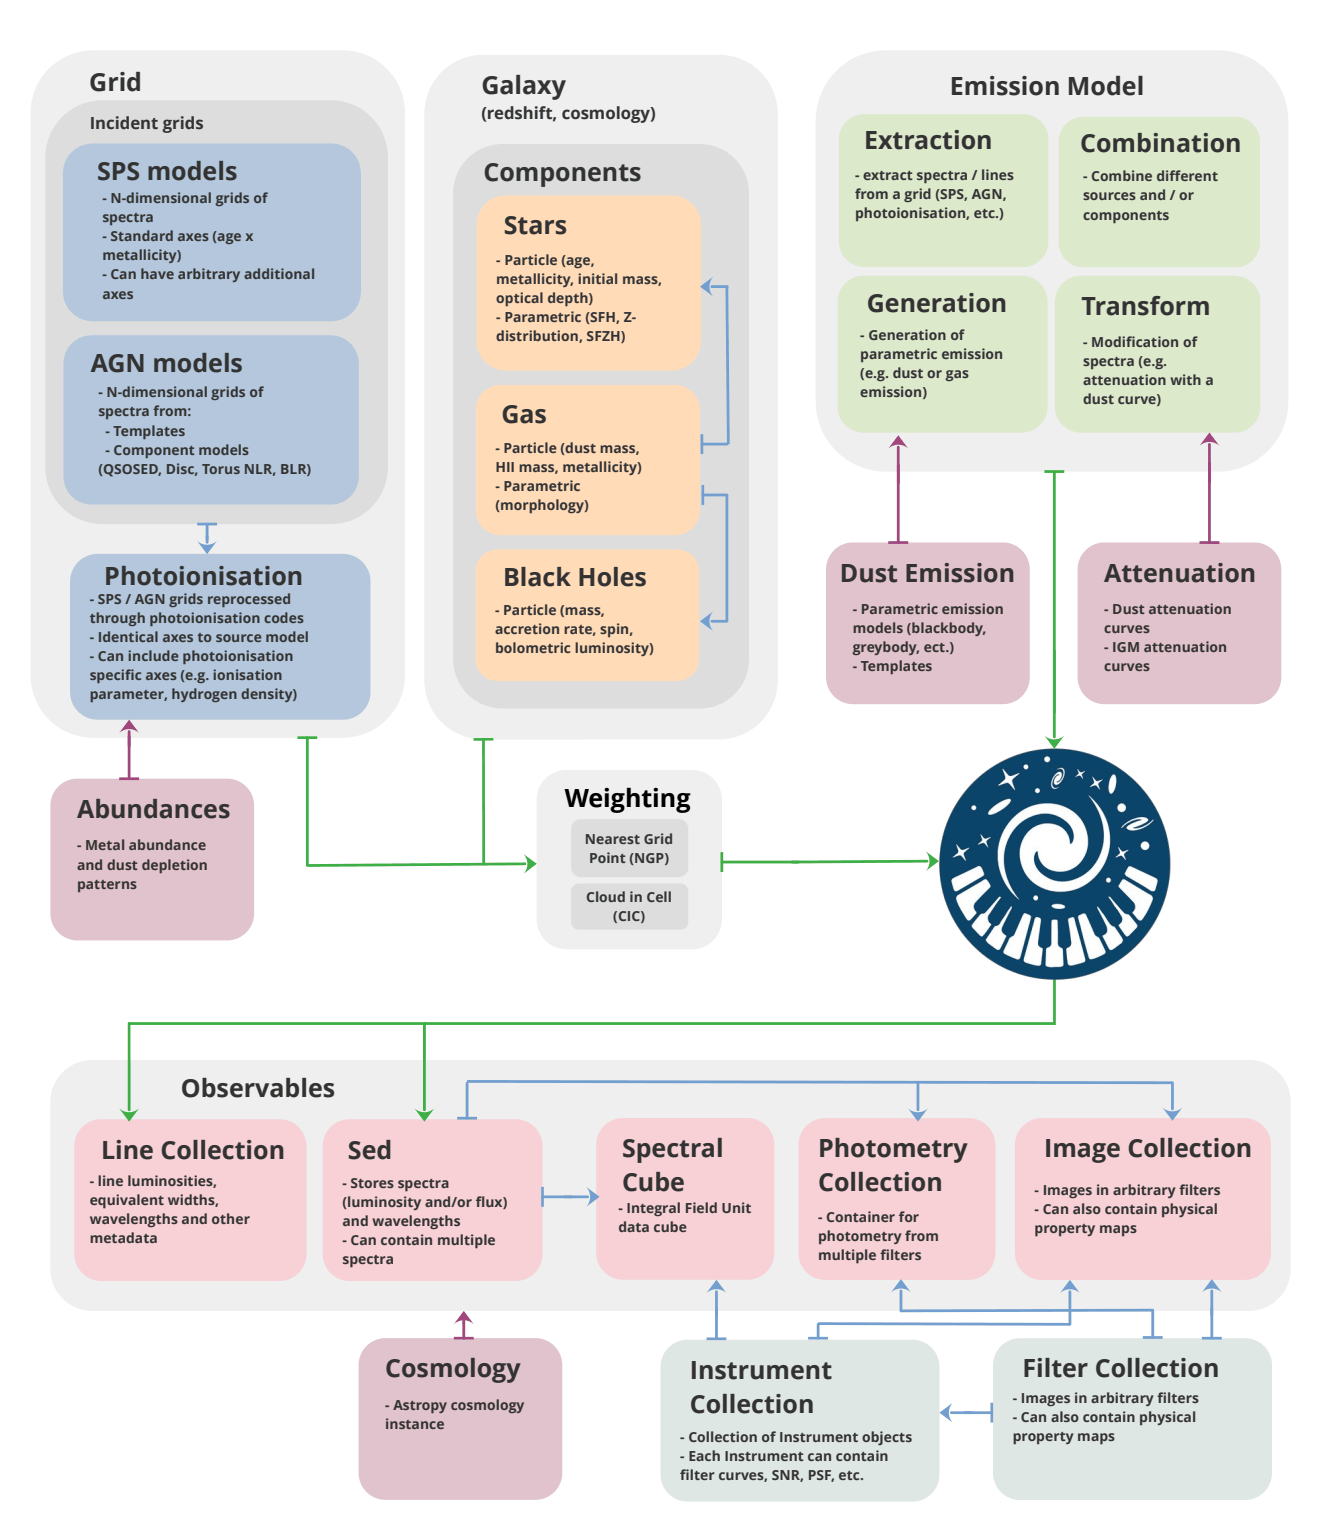

In [ ]:
import os
from IPython.display import Image, display
import requests

# Get Synthesizer module image from Google Drive
image_url = 'https://drive.google.com/uc?export=download&id=1aN9zmFstP1gqP7JvNQqYOBtvgS2NqLik'
local_filename = 'synthesizer_flow.png'

if not os.path.exists(local_filename):
    response = requests.get(image_url)
    with open(local_filename, 'wb') as f:
        f.write(response.content)

display(Image(local_filename))

## Install synthesizer, as well as the other packages we will need for this notebook

Installation instructions for synthesizer. Some of these instructions are needed to get this working on colab, please see the [documentation](https://synthesizer-project.github.io/synthesizer/) for the most up to date and simple install instructions for your machine. Here we install synthesizer with `WITH_OPENMP=1` to make use of synthesizer’s shared memory parallelism.

Run everything up to *"Generating Photometry*" at the start of the session. This should take just over five minutes. **Do not restart the session when prompted, just press cancel!**

In [ ]:
%env SYNTHESIZER_DIR=/content

env: SYNTHESIZER_DIR=/content


In [ ]:
!WITH_OPENMP=1 pip install cosmos-synthesizer[test]

In [ ]:
!synthesizer-init

  🟢 Synthesizer data directory already exists, no need to re-initialize.


Download synthesizer test data

In [ ]:
!synthesizer-download --test-grids

100% 203M/203M [00:10<00:00, 19.0MB/s]
Downloaded test_grid.hdf5 to /content/grids/test_grid.hdf5
100% 19.6M/19.6M [00:01<00:00, 12.8MB/s]
Downloaded test_grid_agn-blr.hdf5 to /content/grids/test_grid_agn-blr.hdf5
100% 19.6M/19.6M [00:01<00:00, 15.8MB/s]
Downloaded test_grid_agn-nlr.hdf5 to /content/grids/test_grid_agn-nlr.hdf5
100% 214k/214k [00:00<00:00, 5.36MB/s]
Downloaded golden_pipeline_reference.hdf5 to /content/grids/golden_pipeline_reference.hdf5


Install LtU-ILI, which we will use later for simulation-based inference

In [ ]:
!git clone https://github.com/maho3/ltu-ili.git

fatal: destination path 'ltu-ili' already exists and is not an empty directory.


In [ ]:
cd ltu-ili/

/content/ltu-ili


In [ ]:
!pip install ".[pytorch]"

Processing ./.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/maho3/tarp.git to /tmp/pip-install-jj0r3hln/tarp_dda7b1355ee24255992a51f3d1072652
  Running command git clone --filter=blob:none --quiet https://github.com/maho3/tarp.git /tmp/pip-install-jj0r3hln/tarp_dda7b1355ee24255992a51f3d1072652
  Resolved https://github.com/maho3/tarp.git to commit 3fc2bfd0280b6239f8e367b7789fb4df8a907e33
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for ltu-ili: filename=ltu_ili-0.1.5-py3-none-any.whl size=45518 sha256=4a826dcf4eb21f23a07be102203f8baca79142ad8175b4379ae8ce6841db9629
  Stored in directory: /tmp/pip-ephem-wheel-cache-et29jj8u/wheels/7b/b9/cd/6677f35d5647dfbc563949267efef7238b19d2f9e4948b97eb
Successfully built ltu-ili
  Attempting uninstall: ltu-ili
    Found existing

In [ ]:
cd ../

/content


In [ ]:
!pip install schwimmbad

Download the CAMELS simulation data.


In [ ]:
sim = 'SIMBA'  # 'Swift-EAGLE'

snapshot_url = f"https://users.flatironinstitute.org/~camels/Sims/{sim}/L25n256/CV/CV_1/snapshot_082.hdf5"
subfind_url = f"https://users.flatironinstitute.org/~camels/Sims/{sim}/L25n256/CV/CV_1/groups_082.hdf5"

!wget {snapshot_url}
!wget {subfind_url}

!ls

--2026-11-10 14:39:05--  https://users.flatironinstitute.org/~camels/Sims/SIMBA/L25n256/CV/CV_1/snapshot_082.hdf5
Resolving users.flatironinstitute.org (users.flatironinstitute.org)... 23.130.84.193, 158.106.193.205
Connecting to users.flatironinstitute.org (users.flatironinstitute.org)|23.130.84.193|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1781270475 (1.7G) [application/octet-stream]
Saving to: ‘snapshot_082.hdf5.1’

snapshot_082.hdf5.1 100%[===================>]   1.66G  52.7MB/s    in 50s     

2026-11-10 14:39:55 (34.3 MB/s) - ‘snapshot_082.hdf5.1’ saved [1781270475/1781270475]

--2026-11-10 14:39:55--  https://users.flatironinstitute.org/~camels/Sims/SIMBA/L25n256/CV/CV_1/groups_082.hdf5
Resolving users.flatironinstitute.org (users.flatironinstitute.org)... 23.130.84.193, 158.106.193.205
Connecting to users.flatironinstitute.org (users.flatironinstitute.org)|23.130.84.193|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 597

# Generating photometry

We first load the CAMELS simulation data into synthesizer. We do this with a dedicated method for CAMELS-SIMBA.

In [ ]:
from synthesizer.load_data.load_camels import load_CAMELS_Simba, load_CAMELS_SwiftEAGLE_subfind
from synthesizer.conversions import lnu_to_absolute_mag
from synthesizer.emission_models import IncidentEmission
from synthesizer.instruments import FilterCollection

# Assuming the files are in the current directory
snapshot_path = 'snapshot_082.hdf5'
subfind_path = 'groups_082.hdf5'

gals = load_CAMELS_Simba(
# gals = load_CAMELS_SwiftEAGLE_subfind(
    './',
    snap_name=snapshot_path,
    group_name=subfind_path
)

/usr/local/lib/python3.13/dist-packages/unyt/array.py:2030: RuntimeWarning: invalid value encountered in divide
  out_arr = func(


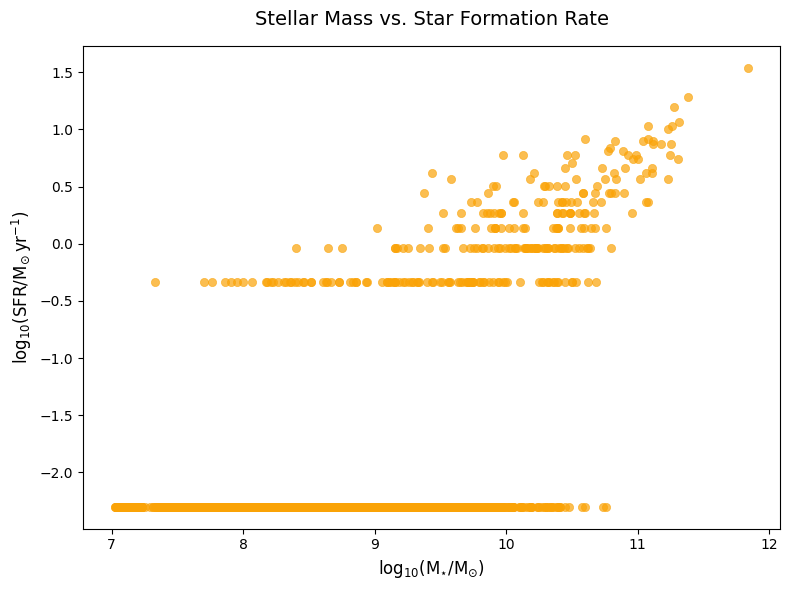

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from unyt import Myr

mstar = np.array([g.stellar_mass for g in gals])

# Here we define SFR as
sfr = np.array([g.stars.get_sfr(timescale=50*Myr) for g in gals])

# Mask out galaxies with zero stellar mass to avoid log10(0) division warnings
valid = (mstar > 0)
mstar_valid = mstar[valid]
sfr_valid = sfr[valid].copy()

# Handle zero SFR safely
sfr_valid[sfr_valid == 0] = 5e-3

plt.figure(figsize=(8, 6), dpi=100)

# Create the scatter plot
plt.scatter(
    np.log10(mstar_valid),
    np.log10(sfr_valid),
    alpha=0.7,
    linewidths=0.5,
    s=35,
    c='#faa307'
)

# Labels and formatting (using single backslashes in raw strings for proper LaTeX compilation)
plt.xlabel(r"$\rm log_{10}(M_{\star} / M_{\odot})$", fontsize=12)
plt.ylabel(r"$\rm log_{10}(SFR / M_{\odot} \, yr^{-1})$", fontsize=12)
plt.title("Stellar Mass vs. Star Formation Rate", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

We now load a grid. [Grids](https://synthesizer-project.github.io/synthesizer/emission_grids/grids.html) are an important concept in Synthesizer, that describe the emission from some source (stellar, AGN, etc.) as a fucntion of some simple axes. In this case, we load a test grid provided with synthesizer, based on the BPASS v2.2.1 binary stellar population synthesis models.

In [ ]:
from unyt import angstrom
from synthesizer.grid import Grid

grid_name = "test_grid"
grid = Grid(grid_name)

print(grid)

+-----------------------------------------------------------------------------------+
|                                       GRID                                        |
+-----------------------------+-----------------------------------------------------+
| Attribute                   | Value                                               |
+-----------------------------+-----------------------------------------------------+
| grid_dir                    | '/content/grids'                                    |
+-----------------------------+-----------------------------------------------------+
| grid_name                   | 'test_grid'                                         |
+-----------------------------+-----------------------------------------------------+
| grid_ext                    | 'hdf5'                                              |
+-----------------------------+-----------------------------------------------------+
| grid_filename               | '/content/grids/test_g

[Emission models](https://synthesizer-project.github.io/synthesizer/emission_models/emission_models.html) are another important concept in Synthesizer, that describe how simulation properties are mapped to emissions. Emission models consist of four main operations: *extraction*, *generation*, *transformation* and *combination*, that can be combined to form arbitrarily complex models. Below we use a very simple premade model, *IncidentEmission*, that just extracts the incident emission directly from a grid.

In [ ]:
incident = IncidentEmission(grid)
print(incident)

|====== EmissionModel: incident ======|
|-------------------------------------|
|  INCIDENT (stellar)                 |
|-------------------------------------|
|Extraction model:                    |
|  Grid: test_grid                    |
|  Extract key: incident              |
|  Use velocity shift: False          |
|  Save emission: True                |
|=====================================|


We now combine these ingredients to generate some spectra and photometry, using a [`Pipeline`](https://synthesizer-project.github.io/synthesizer/pipeline/pipeline.html). This takes an emission model and a list of galaxies, and generates the same observables for every galaxy. The `get_*` methods only flag what we want to compute, and all of the work is then done by `run`. The outputs are stored as arrays on the `Pipeline`, with one row per galaxy.

Photometry needs some filters. Usually we would load these directly from the SVO [database](https://svo2.cab.inta-csic.es/theory/fps/index.php) using their filter codes (e.g. `FilterCollection(filter_codes=["SLOAN/SDSS.g"])`) and attach them to an `Instrument`. For GALEX this doesn't work well: the SVO curves for the GALEX filters are given as an *effective area* (in cm$^2$, folding in the telescope's collecting area) rather than a dimensionless transmission curve between 0 and 1. Synthesizer's `Filter` expects a transmission curve, so the effective area is not what it should be given. Instead, we use Synthesizer's premade `GALEXFUV` instrument, which defines the GALEX far-ultraviolet (FUV) transmission curve directly (and so also needs no download from SVO). We resample the filter onto the grid wavelengths so that it matches our spectra. We will run several pipelines below, so we wrap these steps in some small functions. Each emission model needs its own `Pipeline`. `run` empties the list passed to `add_galaxies`, so we pass a copy to keep `gals` available for later runs.

We first filter our galaxies by stellar mass, then run the pipeline.

In [ ]:
from synthesizer.instruments.premade import GALEXFUV
from synthesizer.conversions import lnu_to_absolute_mag   # needed by get_fuv_mags

from synthesizer.pipeline import Pipeline

# Filter by stellar mass
mstar_mask = np.array([np.sum(g.stars.masses) > 1e9 for g in gals])
gals = [g for g, _m in zip(gals, mstar_mask) if _m]
print(len(gals))


def make_instrument(grid):
      """Create the premade GALEX FUV instrument on the grid wavelengths."""
      return GALEXFUV(filter_lams=grid.lam)


def run_pipeline(model, galaxies, instrument, nthreads=2):
  """Generate the spectra and photometry for an emission model."""
  pipeline = Pipeline(model, nthreads=nthreads, verbose=0)
  pipeline.add_galaxies(list(galaxies))
  pipeline.get_spectra()
  pipeline.get_photometry_luminosities(instrument)
  pipeline.run()
  return pipeline


def get_fuv_mags(pipeline, label):
  """Get the GALEX FUV absolute magnitudes for an emission model label."""
  phot = pipeline.luminosities["Stars"][label]["GALEX/GALEX.FUV"]
  return lnu_to_absolute_mag(phot)


instrument = make_instrument(grid)
pipeline = run_pipeline(incident, gals, instrument)

621


Let's visualise some of these spectra, which the `Pipeline` stores in its `lnu_spectra` attribute.

Text(0, 0.5, '$L_{\\nu} \\,/\\, \\mathrm{erg \\, s^{-1} \\, Hz^{-1}}$')

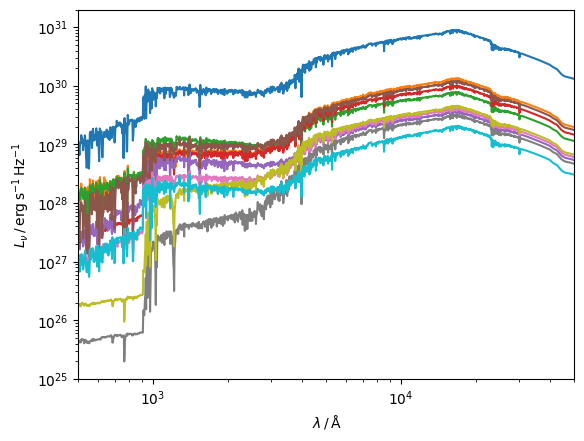

In [ ]:
lnu = pipeline.lnu_spectra["Stars"]["incident"]

fig, ax = plt.subplots()
ax.loglog(grid.lam, lnu[:10].T)

ax.set_xlim(5e2, 5e4)
ax.set_ylim(1e25, 2e31)
ax.set_xlabel(r"$\lambda \,/\, \mathrm{\AA}$")
ax.set_ylabel(r"$L_{\nu} \,/\, \mathrm{erg \, s^{-1} \, Hz^{-1}}$")

The `Pipeline` has also generated the photometry, stored in its `luminosities` attribute. We convert this photometry from spectral luminosity units to absolute magnitudes.

In [ ]:
# Calculate FUV magnitudes
mags = get_fuv_mags(pipeline, "incident")

We can now plot our FUV luminosity function.

In [ ]:
def calc_df(x, volume, binLimits):
    hist, dummy = np.histogram(x, bins=binLimits)
    hist = np.float64(hist)
    phi = (hist / volume) / (binLimits[1] - binLimits[0])

    phi_sigma = (np.sqrt(hist) / volume) / (
        binLimits[1] - binLimits[0]
    )  # Poisson errors

    return phi, phi_sigma, hist

h = 0.677

# Calculate FUV luminosity function
binlims = np.linspace(-25, -14, 12)
bins = binlims[:-1] + (binlims[1] - binlims[0]) / 2
phi, phi_sigma, _ = calc_df(mags, (25 / h) ** 3, binlims)

/tmp/ipykernel_19515/65461271.py:7: RuntimeWarning: divide by zero encountered in log10
  log_phi = np.log10(phi)
/tmp/ipykernel_19515/65461271.py:8: RuntimeWarning: divide by zero encountered in log10
  log_phi_upper = np.log10(phi + phi_sigma)


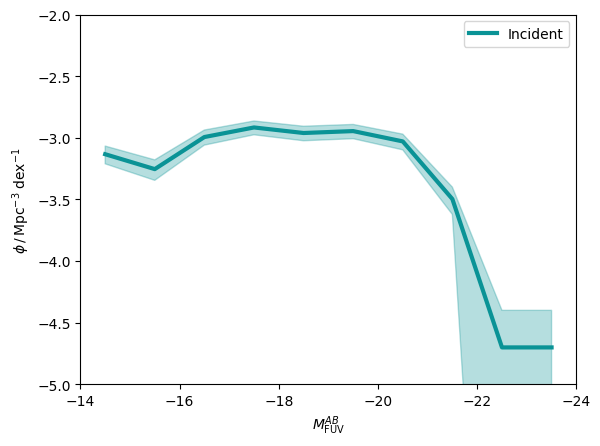

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)

# Calculate log10 values and bounds safely
log_phi = np.log10(phi)
log_phi_upper = np.log10(phi + phi_sigma)
# For lower bound, clip to avoid log10 on negative/zero values
log_phi_lower = np.log10(np.clip(phi - phi_sigma, 1e-10, None))

ax.plot(bins, log_phi, label="Incident", lw=3, color='#0a9396')
ax.fill_between(bins, log_phi_lower, log_phi_upper, color='#0a9396', alpha=0.3)

ax.legend()
ax.set_xlabel(r"$M_{\rm FUV}^{AB}$")
ax.set_ylabel(r"$\phi \,/\, \mathrm{Mpc^{-3} \; dex^{-1}}$")
ax.set_xlim(-14, -24)
ax.set_ylim(-5,-2)
plt.show()

# Can we speed this up?

The main limitation on the speed of the spectra calculation is the resolution of the wavelength grid. We can resample our grid to only include the wavelengths we are interested in. Here we choose these to be the rest-frame ultraviolet around the GALEX FUV filter: $1000 < \lambda \,/\, Å < 2500$

In [ ]:
mask = (grid.lam > 1000 * angstrom) & (grid.lam < 2500 * angstrom)
grid.interp_spectra(new_lam=grid.lam[mask])

/tmp/ipykernel_19515/3228702841.py:2: RuntimeWarning: 
201 lines are outside the wavelength range of the grid and will be removed.
  grid.interp_spectra(new_lam=grid.lam[mask])


In [ ]:
incident = IncidentEmission(grid)
instrument = make_instrument(grid)
pipeline = run_pipeline(incident, gals, instrument)

# What about dust?

If we want to include dust we simply need to update our emission model. Below, we add a transformation emission model component, `StellarEmissionModel`, to apply a power law dust curve with a fixed optical depth. We print this model, and plot the tree; **this is still a very simple model**, with only an extraction and transformation, so the tree only consists of two leaves connected by a dashed line. See the documentation on [emission models](https://synthesizer-project.github.io/synthesizer/emission_models/emission_models.html) for more complicated examples, such as how to calculate the amount of attenuation that depends on a given line of sight.

|===================================== EmissionModel: attenuated =====================================|
|-----------------------------------------------------------------------------------------------------|
|  ATTENUATED (stellar)                                                                               |
|-----------------------------------------------------------------------------------------------------|
|Transformer model:                                                                                   |
|  Transformer: <class 'synthesizer.emission_models.transformers.dust_attenuation.PowerLaw'>          |
|  Apply to: incident                                                                                 |
|  Save emission: True                                                                                |
|  Fixed parameters:                                                                                  |
|    - tau_v: 0.33                                              

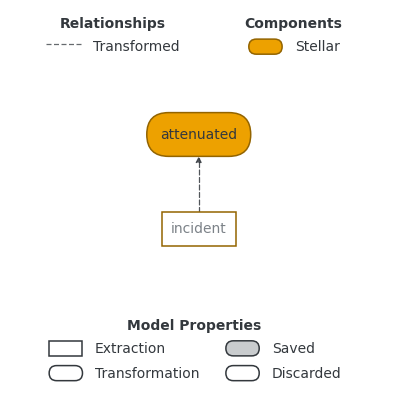

(<Figure size 377.494x379.167 with 1 Axes>, <Axes: >)

In [ ]:
from synthesizer.emission_models import StellarEmissionModel
from synthesizer.emission_models.attenuation import PowerLaw

incident = StellarEmissionModel(
    "incident",
    grid=grid,
    extract="incident",
    emitter="stellar",
    save=False,
)

attenuated = StellarEmissionModel(
    "attenuated",
    dust_curve=PowerLaw(slope=-1),
    apply_to=incident,
    tau_v=0.33
)
print(attenuated)
attenuated.plot_emission_graph()

To generate new spectra and photometry, we just pass this new emission model to a new `Pipeline`.

In [ ]:
pipeline = run_pipeline(attenuated, gals, instrument)
mags = get_fuv_mags(pipeline, "attenuated")

phi_att, phi_att_sigma, _ = calc_df(mags, (25 / h) ** 3, binlims)

/tmp/ipykernel_19515/1185116275.py:7: RuntimeWarning: divide by zero encountered in log10
  log_phi = np.log10(phi)
/tmp/ipykernel_19515/1185116275.py:8: RuntimeWarning: divide by zero encountered in log10
  log_phi_upper = np.log10(phi + phi_sigma)
/tmp/ipykernel_19515/1185116275.py:12: RuntimeWarning: divide by zero encountered in log10
  log_phi_att = np.log10(phi_att)
/tmp/ipykernel_19515/1185116275.py:13: RuntimeWarning: divide by zero encountered in log10
  log_phi_att_upper = np.log10(phi_att + phi_att_sigma)


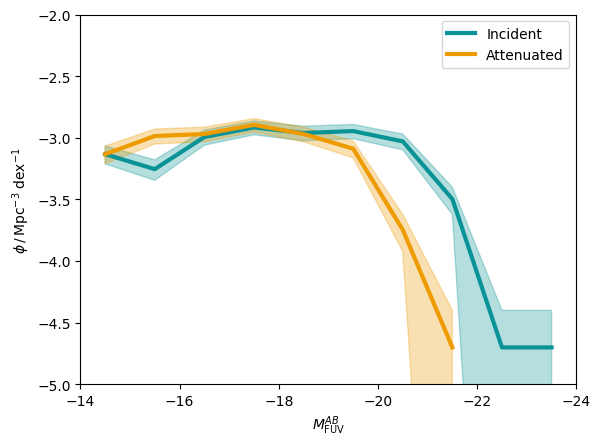

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)

# Safely calculate log10 values and bounds for Incident
log_phi = np.log10(phi)
log_phi_upper = np.log10(phi + phi_sigma)
log_phi_lower = np.log10(np.clip(phi - phi_sigma, 1e-10, None))

# Safely calculate log10 values and bounds for Attenuated
log_phi_att = np.log10(phi_att)
log_phi_att_upper = np.log10(phi_att + phi_att_sigma)
log_phi_att_lower = np.log10(np.clip(phi_att - phi_att_sigma, 1e-10, None))

# Plot Incident with its specific color
ax.plot(bins, log_phi, label="Incident", lw=3, color='#0a9396')
ax.fill_between(bins, log_phi_lower, log_phi_upper, color='#0a9396', alpha=0.3)

# Plot Attenuated
ax.plot(bins, log_phi_att, label="Attenuated", lw=3, color='#ee9b00')
ax.fill_between(bins, log_phi_att_lower, log_phi_att_upper, color='#ee9b00', alpha=0.3)

ax.legend()
ax.set_xlabel(r"$M_{\rm FUV}^{AB}$")
ax.set_ylabel(r"$\phi \,/\, \mathrm{Mpc^{-3} \; dex^{-1}}$")
ax.set_xlim(-14, -24)
ax.set_ylim(-5, -2)
plt.show()

# Including nebular emission

Our test grid has been reprocessed through Cloudy, a photoionisation code that predicts the nebular line and continuum emission. As such, we have a number of additional spectra and also *lines* that we can explore. The full list of grids that we have processed through Cloudy can be found in [Syndex](https://synthesizer-project.org/syndex/search?q=AGN&sort=photoionised&direction=asc&type=grid).

We reload the grid to restore the full wavelength range, and list the available spectra.

In [ ]:
grid = Grid("test_grid")
grid.available_emissions

['transmitted', 'linecont', 'incident', 'nebular', 'nebular_continuum']

Let's update our emission model to use the *nebular* emission (including line and continuum emission) alongside the transmitted emission. We wrap this in a function, as we will use the same model with other grids below.

In [ ]:
def attenuatedemissionmodel(grid):
  transmitted = StellarEmissionModel(
      "transmitted",
      grid=grid,
      extract="transmitted",
      emitter="stellar",
      save=False,
  )

  nebular = StellarEmissionModel(
      "nebular",
      grid=grid,
      extract="nebular",
      emitter="stellar",
      save=False,
  )

  intrinsic = StellarEmissionModel(
      "intrinsic",
      combine=(transmitted, nebular),
      save=False,
  )

  return StellarEmissionModel(
      "attenuated",
      dust_curve=PowerLaw(slope=-1),
      apply_to=intrinsic,
      tau_v=0.33,
  )

attenuated = attenuatedemissionmodel(grid)

In [ ]:
instrument = make_instrument(grid)
pipeline = run_pipeline(attenuated, gals[:10], instrument)

Text(0, 0.5, '$L_{\\nu} \\,/\\, \\mathrm{erg \\, s^{-1} \\, Hz^{-1}}$')

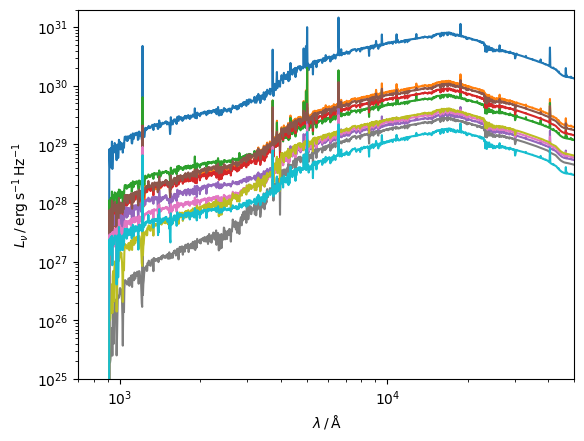

In [ ]:
lnu = pipeline.lnu_spectra["Stars"]["attenuated"]

fig, ax = plt.subplots()
ax.loglog(grid.lam, lnu.T)

ax.set_xlim(7e2, 5e4)
ax.set_ylim(1e25, 2e31)
ax.set_xlabel(r"$\lambda \,/\, \mathrm{\AA}$")
ax.set_ylabel(r"$L_{\nu} \,/\, \mathrm{erg \, s^{-1} \, Hz^{-1}}$")

We can clearly see that for some galaxies there are strong emission lines, including Lyman-$\alpha$.

We can also look at the emission from individual lines. These grids have a large number of different lines, following the Cloudy naming convention, for which luminosities, equivalent widths and other properties are available.

In [ ]:
print(grid.available_lines)

['He 2 1025.27A' 'O 6 1031.91A' 'O 6 1037.61A' 'He 2 1084.94A'
 'Si 2 1179.59A' 'Si 3 1206.50A' 'He 2 1215.13A' 'H 1 1215.67A'
 'O 5 1218.34A' 'N 5 1238.82A' 'N 5 1242.80A' 'Si 2 1260.42A'
 'Si 2 1264.74A' 'Si 2 1265.00A' 'O 1 1302.17A' 'O 1 1304.86A'
 'O 1 1306.03A' 'C 2 1334.53A' 'C 2 1335.66A' 'C 2 1335.71A'
 'Si 4 1393.75A' 'O 4 1399.78A' 'O 4 1401.16A' 'Si 4 1402.77A'
 'O 4 1404.81A' 'O 4 1407.38A' 'N 4 1486.50A' 'Si 2 1526.71A'
 'Si 2 1533.43A' 'C 4 1548.19A' 'C 4 1550.77A' 'Ne 4 1601.45A'
 'He 2 1640.41A' 'O 1 1641.31A' 'C 1 1657.91A' 'O 3 1660.81A'
 'O 3 1666.15A' 'Al 2 1670.79A' 'N 3 1749.67A' 'Mg 6 1806.00A'
 'Si 3 1882.71A' 'Si 3 1892.03A' 'C 3 1906.68A' 'C 3 1908.73A'
 'C 1 1992.01A' 'Si 7 2146.64A' 'O 3 2320.95A' 'C 2 2325.40A'
 'C 2 2326.93A' 'Fe 2 2395.63A' 'Fe 2 2399.24A' 'Fe 2 2406.66A'
 'Fe 2 2410.52A' 'C 1 2582.90A' 'Fe 2 2598.37A' 'Fe 2 2607.09A'
 'Fe 2 2611.87A' 'Fe 2 2613.82A' 'Fe 2 2625.67A' 'Fe 2 2628.29A'
 'Mg 7 2628.89A' 'Fe 2 2631.05A' 'Fe 2 2631.32A' 'Mg 5 2

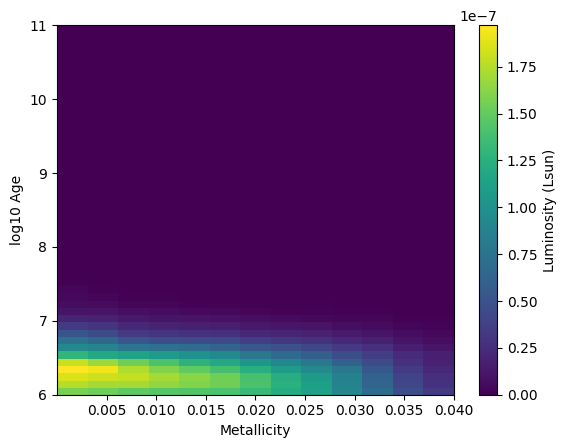

In [ ]:
lc = grid.get_lines_for_full_grid('H 1 3734.37A')
plt.imshow(
    lc.get_flux0()[0],
    origin='lower',
    aspect='auto',
    extent=[
        grid.axes_values['metallicities'][0],
        grid.axes_values['metallicities'][-1],
        np.log10(grid.axes_values['ages'][0]),
        np.log10(grid.axes_values['ages'][-1])
    ]
)
plt.xlabel('Metallicity')
plt.ylabel(f'log10 Age')
plt.colorbar(label=f'Luminosity ({grid.line_lums["nebular"].units})')

We also provide functionality for producing common line diagnostic plots, such as the BPT diagram. Here we plot the values from the grid at fixed age, for a range of metallicities.

/usr/local/lib/python3.13/dist-packages/synthesizer/emissions/line_ratios.py:174: RuntimeWarning: overflow encountered in power
  ax.loglog(10**logNII_Ha, 10**logOIII_Hb, **kwargs)


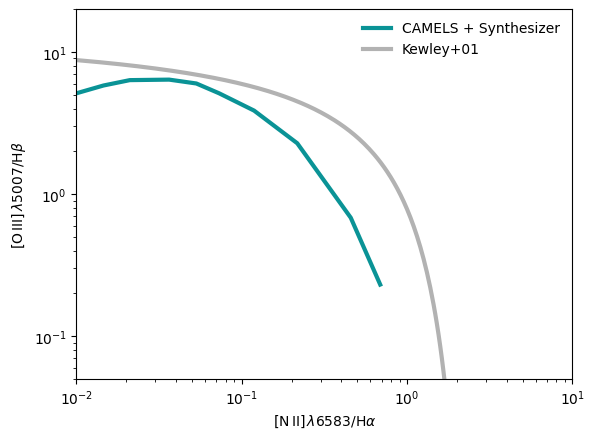

In [ ]:
from synthesizer.emissions import line_ratios
import numpy as np
import matplotlib.pyplot as plt

diagram_id = "BPT-NII"
ia = 0  # this is 1 Myr old for the test grid
x = []
y = []
for iZ, Z in enumerate(grid.metallicities):
    grid_point = (ia, iZ)
    lines = grid.get_lines(grid_point)
    x_, y_ = lines.get_diagram(diagram_id)
    x.append(x_)
    y.append(y_)

# Plot the Kewley SF/AGN dividing line
fig, ax = plt.subplots()

# Customised color and line width for the test grid results
ax.plot(x, y, color='#0a9396', lw=3, label='CAMELS + Synthesizer')

logNII_Ha = np.arange(-2.0, 1.0, 0.01)
# Set show=False so that we can add our legend before displaying the figure
logOIII_Hb = line_ratios.plot_bpt_kewley01(
    logNII_Ha, fig=fig, ax=ax, show=False, c="k", lw="3", alpha=0.3,
    label='Kewley+01'
)

ax.legend(loc='upper right',frameon=False)
plt.show()

Let's reduce the wavelength range again, and see how the nebular emission changes the FUV luminosity function.

In [ ]:
mask = (grid.lam > 1000 * angstrom) & (grid.lam < 2500 * angstrom)
grid.interp_spectra(new_lam=grid.lam[mask])

/tmp/ipykernel_19515/3228702841.py:2: RuntimeWarning: 
201 lines are outside the wavelength range of the grid and will be removed.
  grid.interp_spectra(new_lam=grid.lam[mask])


/tmp/ipykernel_19515/3344799889.py:11: RuntimeWarning: divide by zero encountered in log10
  log_phi_att = np.log10(phi_att)
/tmp/ipykernel_19515/3344799889.py:12: RuntimeWarning: divide by zero encountered in log10
  log_phi_att_upper = np.log10(phi_att + phi_att_sigma)
/tmp/ipykernel_19515/3344799889.py:16: RuntimeWarning: divide by zero encountered in log10
  log_phi_nebular = np.log10(phi_nebular)
/tmp/ipykernel_19515/3344799889.py:17: RuntimeWarning: divide by zero encountered in log10
  log_phi_nebular_upper = np.log10(phi_nebular + phi_nebular_sigma)


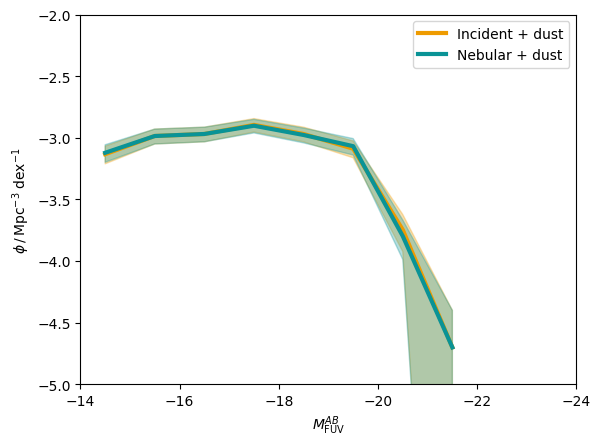

In [ ]:
attenuated = attenuatedemissionmodel(grid)
instrument = make_instrument(grid)
pipeline = run_pipeline(attenuated, gals, instrument)
mags = get_fuv_mags(pipeline, "attenuated")

phi_nebular, phi_nebular_sigma, _ = calc_df(mags, (25 / h) ** 3, binlims)

fig, ax = plt.subplots(1, 1)

# Safely calculate log10 values and bounds for Incident + Dust
log_phi_att = np.log10(phi_att)
log_phi_att_upper = np.log10(phi_att + phi_att_sigma)
log_phi_att_lower = np.log10(np.clip(phi_att - phi_att_sigma, 1e-10, None))

# Safely calculate log10 values and bounds for Nebular + Dust
log_phi_nebular = np.log10(phi_nebular)
log_phi_nebular_upper = np.log10(phi_nebular + phi_nebular_sigma)
log_phi_nebular_lower = np.log10(np.clip(phi_nebular - phi_nebular_sigma, 1e-10, None))

# Plot Incident + Dust
ax.plot(bins, log_phi_att, label="Incident + dust", lw=3, color='#ee9b00')
ax.fill_between(bins, log_phi_att_lower, log_phi_att_upper, color='#ee9b00', alpha=0.3)

# Plot Nebular + Dust
ax.plot(bins, log_phi_nebular, label="Nebular + dust", lw=3, color='#0a9396')
ax.fill_between(bins, log_phi_nebular_lower, log_phi_nebular_upper, color='#0a9396', alpha=0.3)

ax.legend()
ax.set_xlabel(r"$M_{\rm FUV}^{AB}$")
ax.set_ylabel(r"$\phi \,/\, \mathrm{Mpc^{-3} \; dex^{-1}}$")
ax.set_xlim(-14, -24)
ax.set_ylim(-5, -2)
plt.show()

## Changing the SPS model

We can test how sensitive our results are to various ingredients in our model. We will show this by swapping out the Stellar Population Synthesis (SPS) model, comparing the BPASS test grid to a BC03 grid. The available grids are listed in [Syndex](https://synthesizer-project.org/syndex), and can be downloaded by name.

In [ ]:
!synthesizer-download --dataset bc03-2003-padova2000-chabrier03-0p1-100-cloudy-c23p01

100% 403M/403M [00:11<00:00, 34.8MB/s]
Downloaded bc03-2003-padova00_chabrier03-0.1,100_cloudy-c23.01-sps.hdf5 to /content/grids/bc03-2003-padova00_chabrier03-0.1,100_cloudy-c23.01-sps.hdf5


We load the new grid, reduce its wavelength range in the same way, and pass the same emission model to a new `Pipeline`. We only use this grid for this comparison; the rest of the notebook uses the test grid.

/tmp/ipykernel_19515/114118135.py:4: RuntimeWarning: 
201 lines are outside the wavelength range of the grid and will be removed.
  grid_bc03.interp_spectra(new_lam=grid_bc03.lam[mask])
/tmp/ipykernel_19515/114118135.py:12: RuntimeWarning: divide by zero encountered in log10
  ax.plot(bins, np.log10(phi_nebular), label="BPASS", color='#0a9396', lw=3)
/tmp/ipykernel_19515/114118135.py:13: RuntimeWarning: divide by zero encountered in log10
  ax.plot(bins, np.log10(phi_bc03), label="BC03", color='#ee9b00', lw=3)


(-14.0, -24.0)

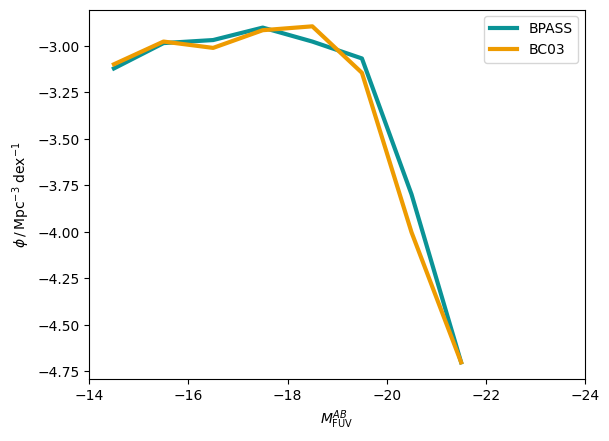

In [ ]:
grid_bc03 = Grid("bc03-2003-padova00_chabrier03-0.1,100_cloudy-c23.01-sps")

mask = (grid_bc03.lam > 1000 * angstrom) & (grid_bc03.lam < 2500 * angstrom)
grid_bc03.interp_spectra(new_lam=grid_bc03.lam[mask])

pipeline = run_pipeline(attenuatedemissionmodel(grid_bc03), gals, make_instrument(grid_bc03))
mags = get_fuv_mags(pipeline, "attenuated")

phi_bc03, _, _ = calc_df(mags, (25 / h) ** 3, binlims)

fig, ax = plt.subplots(1, 1)
ax.plot(bins, np.log10(phi_nebular), label="BPASS", color='#0a9396', lw=3)
ax.plot(bins, np.log10(phi_bc03), label="BC03", color='#ee9b00', lw=3)
ax.legend()
ax.set_xlabel(r"$M_{\rm FUV}^{AB}$")
ax.set_ylabel(r"$\phi \,/\, \mathrm{Mpc^{-3} \; dex^{-1}}$")
ax.set_xlim(-14, -24)

# Calibrating the dust model

Can we fit some of these parameters in our dust model, such as the optical depth and slope of the attenuation law? Here we present a somewhat over engineered example, using Simulation Based Inference (SBI) to infer posteriors on these parameters, derived from our forward modelled data. SBI has a number of neat advantages over traditional inference approaches, utilising neural density estimators to directly model the relationship between data and parameters.

We will use the [LtU-ILI package](https://github.com/maho3/ltu-ili/tree/main) to build a Neural Posterior Estimation (NPE) model.

In [ ]:
import torch

import ili
from ili.dataloaders import NumpyLoader
from ili.inference import InferenceRunner
from ili.validation.metrics import PosteriorCoverage, PlotSinglePosterior

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cpu


We create a slightly more complex emission model for this example, utilising a two component screen inspired by Charlot & Fall 2000. For simplicity, stars younger than 10 Myr are attenuated by a birth cloud screen, and older stars by an ISM screen. We then define a function that takes a set of dust parameters, builds the corresponding emission model, runs a `Pipeline`, and returns the luminosity function calculated from the `Pipeline` outputs.

In [ ]:
from unyt import Myr


def intrinsicemissionmodel(grid, age_op):
  transmitted = StellarEmissionModel(
      "transmitted"+age_op,
      grid=grid,
      extract="transmitted",
      emitter="stellar",
      mask_attr="ages",
      mask_thresh=10 * Myr,
      mask_op=age_op,
      save=False,
  )

  nebular = StellarEmissionModel(
      "nebular"+age_op,
      grid=grid,
      extract="nebular",
      emitter="stellar",
      mask_attr="ages",
      mask_thresh=10 * Myr,
      mask_op=age_op,
      save=False,
  )

  return StellarEmissionModel(
      "intrinsic"+age_op,
      combine=(transmitted, nebular),
      save=False,
  )

intrinsic_young = intrinsicemissionmodel(grid, '<')
intrinsic_old = intrinsicemissionmodel(grid, '>')
instrument = make_instrument(grid)


def attenuated_luminosity_function(params):
  """Run a Pipeline for a set of dust parameters and return the FUV LF.

  The parameters are [tau_ism, tau_birth_cloud, slope_ism, slope_birth_cloud].
  """
  attenuated_young = StellarEmissionModel(
      "attenuated<",
      dust_curve=PowerLaw(slope=params[3]),
      apply_to=intrinsic_young,
      tau_v=params[1],
      emitter="stellar",
      save=False,
  )

  attenuated_old = StellarEmissionModel(
      "attenuated>",
      dust_curve=PowerLaw(slope=params[2]),
      apply_to=intrinsic_old,
      tau_v=params[0],
      emitter="stellar",
      save=False,
  )

  attenuated = StellarEmissionModel(
      "attenuated",
      combine=(attenuated_young, attenuated_old),
      emitter="stellar",
  )

  pipeline = run_pipeline(attenuated, gals, instrument)
  mags = get_fuv_mags(pipeline, "attenuated")
  return calc_df(mags, (25 / h) ** 3, binlims)[0]

We then create a latin hypercube of four parameters: the ISM optical depth, the birth cloud optical depth, and the slope of the attenuation curve for the ISM and birth cloud dust. The optical depth bounds mean that the birth clouds are always at least as optically thick as the ISM.

In [ ]:
from scipy.stats import qmc
from tqdm import tqdm

sampler = qmc.LatinHypercube(d=4)
sample = sampler.random(n=100)

l_bounds = [0.1, 0.5, -2, -2]
u_bounds = [0.5, 1.0, -0.5, -0.5]
theta = qmc.scale(sample, l_bounds, u_bounds)

We now loop over these parameters, running a `Pipeline` for each combination of parameters and calculating the luminosity function from its output photometry.

In [ ]:
phi_att = [attenuated_luminosity_function(_params) for _params in tqdm(theta)]

  0%|          | 0/100 [00:00<?, ?it/s]/tmp/ipykernel_19515/2218415153.py:23: RuntimeWarning: 
A mask has filtered out all particles, returning empty Sed
  pipeline.run()
100%|██████████| 100/100 [08:05<00:00,  4.86s/it]


The figure below shows the 10th-90th percentile range of our example luminosity functions:

/tmp/ipykernel_19515/2852046238.py:3: RuntimeWarning: divide by zero encountered in log10
  ax.plot(bins, np.log10(phi_nebular), label="Fiducial", lw=3, color='#ee9b00')
/tmp/ipykernel_19515/2852046238.py:4: RuntimeWarning: divide by zero encountered in log10
  ax.fill_between(bins, np.log10(np.percentile(phi_att, 10, axis=0)), np.log10(np.percentile(phi_att, 90, axis=0)), color='grey', alpha=0.3)


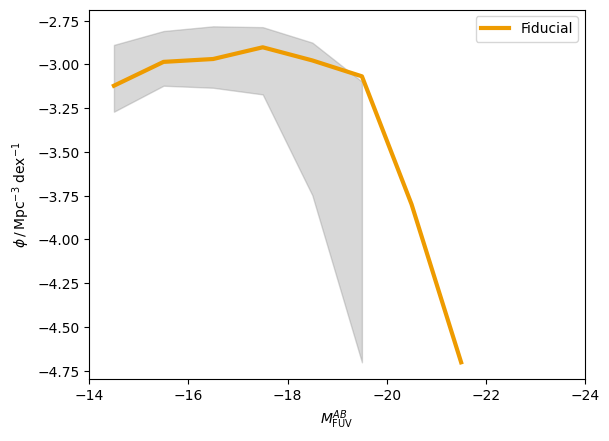

In [ ]:
fig, ax = plt.subplots(1, 1)

ax.plot(bins, np.log10(phi_nebular), label="Fiducial", lw=3, color='#ee9b00')
ax.fill_between(bins, np.log10(np.percentile(phi_att, 10, axis=0)), np.log10(np.percentile(phi_att, 90, axis=0)), color='grey', alpha=0.3)

ax.legend()
ax.set_xlabel(r"$M_{\rm FUV}^{AB}$")
ax.set_ylabel(r"$\phi \,/\, \mathrm{Mpc^{-3} \; dex^{-1}}$")
ax.set_xlim(-14, -24)

plt.show()

## Simulation Based Inference

We load our data x (binned luminosity function) and parameters theta, set our priors to be flat over the same range as the proposal distribution, and combine two Masked Autoregressive Flows (MAF) with a Mixture Density Network (MDN) to model the posterior. We set some hyperparameters for the training, such as batch size and learning rate. **In a real science case we would optimise these parameters using e.g. Optuna.**

In [ ]:
# make a dataloader
loader = NumpyLoader(x=phi_att, theta=theta)

# define a prior
prior = ili.utils.Uniform(low=l_bounds, high=u_bounds, device=device)

# instantiate the neural networks in our ensemble
nets = [
    ili.utils.load_nde_sbi(engine='NPE', model='maf', hidden_features=50, num_transforms=5),
    ili.utils.load_nde_sbi(engine='NPE', model='maf', hidden_features=50, num_transforms=5),
    ili.utils.load_nde_sbi(engine='NPE', model='mdn', hidden_features=50, num_components=6)
]

# define training arguments
train_args = {
    'training_batch_size': 32,
    'learning_rate': 1e-4
}

# initialize the trainer
runner = InferenceRunner.load(
    backend='sbi',
    engine='NPE',
    prior=prior,
    nets=nets,
    device=device,
    train_args=train_args,
    proposal=None,
    out_dir=None
)

In [ ]:
# train the model
posterior_ensemble, summaries = runner(loader=loader)

/usr/local/lib/python3.13/dist-packages/ili/utils/import_utils.py:23: FutureWarning: `sbi.inference.SNPE` is deprecated since sbi v0.27.0 and will be removed in v0.28.0. Use `sbi.inference.NPE_C` instead.
  return getattr(module, class_name)
/usr/local/lib/python3.13/dist-packages/ili/inference/runner_sbi.py:329: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  x = torch.Tensor(loader.get_all_data()).to(self.device)
/usr/local/lib/python3.13/dist-packages/sbi/inference/trainers/npe/npe_base.py:211: UserWarning: Data has constant values in dimension(s) [0, 1]. These dimensions carry no information and will be mapped to zero after z-scoring. Consider removing constant features from your data.
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 457 epochs.

/usr/local/lib/python3.13/dist-packages/sbi/inference/posteriors/ensemble_posterior.py:176: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self._weights = torch.tensor(weights) / sum(weights)


We can visualise our training curves to make sure we're not overfitting.

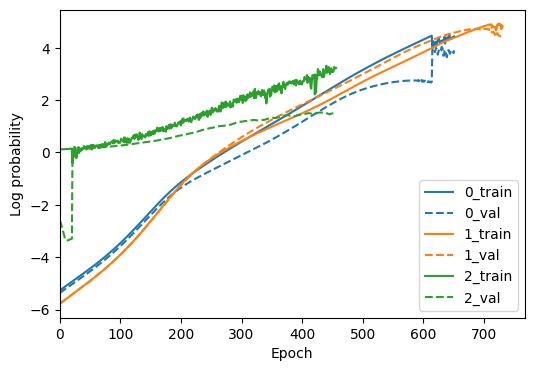

In [ ]:
import matplotlib.colors as mcolors

# plot train/validation loss
fig, ax = plt.subplots(1, 1, figsize=(6,4))
c = list(mcolors.TABLEAU_COLORS)
for i, m in enumerate(summaries):
    ax.plot(m['training_log_probs'], ls='-', label=f"{i}_train", c=c[i])
    ax.plot(m['validation_log_probs'], ls='--', label=f"{i}_val", c=c[i])
ax.set_xlim(0)
ax.set_xlabel('Epoch')
ax.set_ylabel('Log probability')
ax.legend()

We can now visualise our results predicting the posterior for a given simulation. We choose a random index (0) and generate our posterior, and compare to the true value.

  0%|          | 0/332 [00:00<?, ?it/s]

  0%|          | 0/641 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

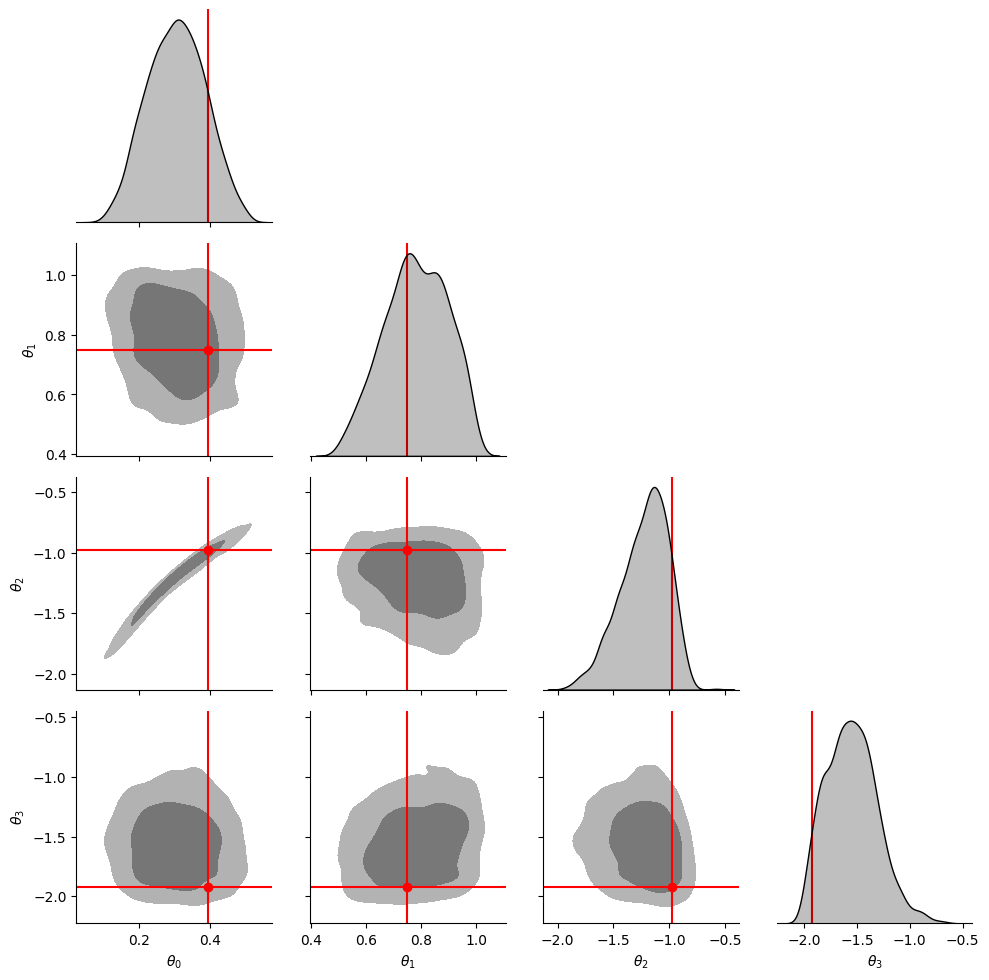

In [ ]:
ind = 0

# use ltu-ili's built-in validation metrics to plot the posterior for this point
metric = PlotSinglePosterior(
    num_samples=1000, sample_method='direct',
    labels=[f'$\\theta_{i}$' for i in range(4)]
)
fig = metric(
    posterior=posterior_ensemble,
    x_obs = phi_att[ind], theta_fid=theta[ind],
    plot_kws=dict(fill=True)
)

We can also generate some coverage and posterior predictive checks. These show how well our NPE is learning an unbiased and accurate representation of the posterior.

100%|██████████| 100/100 [00:01<00:00, 69.03it/s]


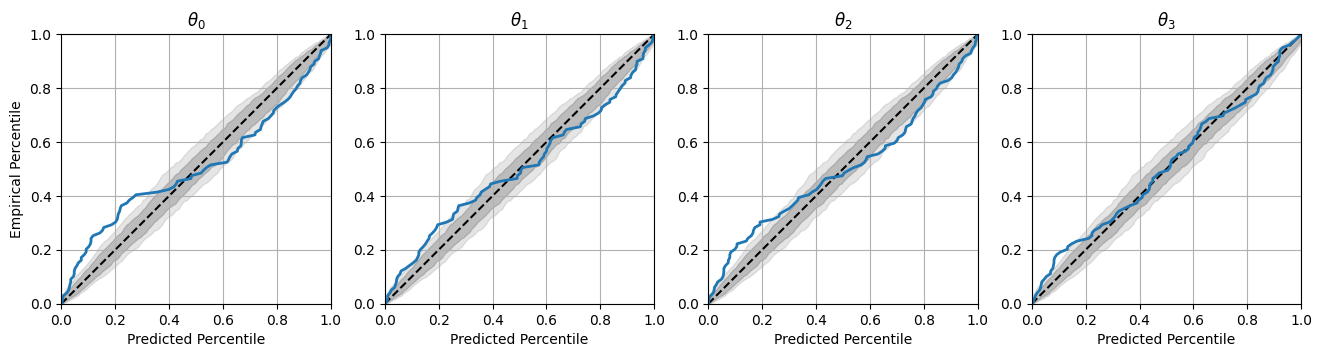

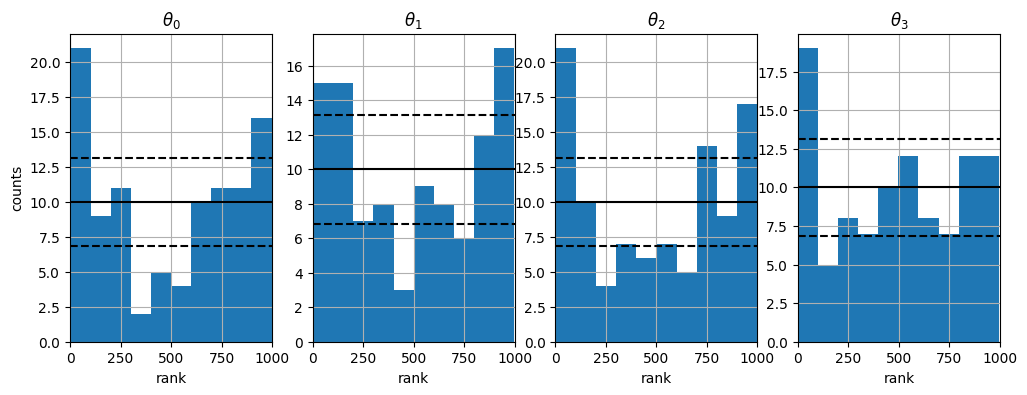

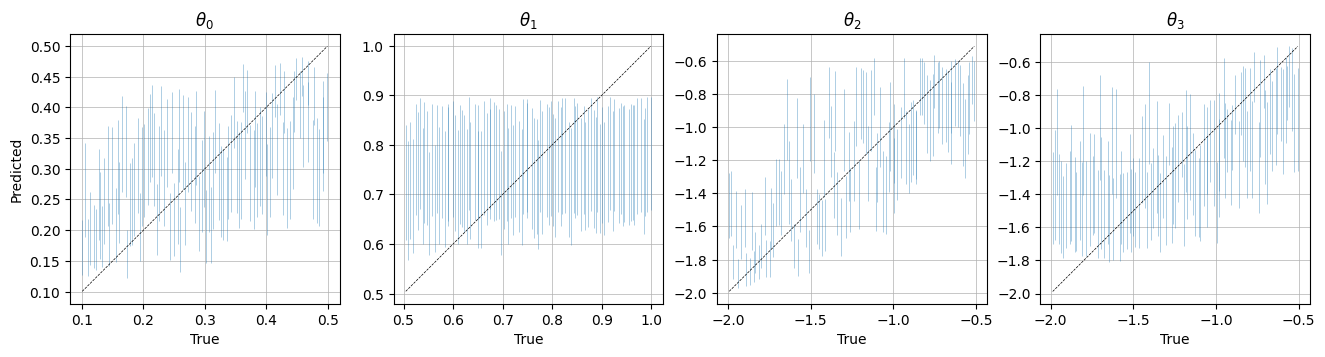

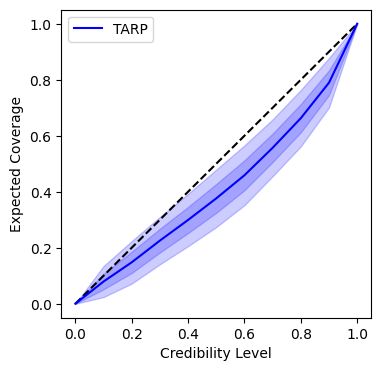

In [ ]:
# Drawing samples from the ensemble posterior

metric = PosteriorCoverage(
    num_samples=1000, sample_method='direct',
    labels=[f'$\\theta_{i}$' for i in range(4)],
    plot_list = ["coverage", "histogram", "predictions", "tarp"],
    out_dir=None
)

fig = metric(
    posterior=posterior_ensemble, # NeuralPosteriorEnsemble instance from sbi package
    x=phi_att, theta=theta
)

Let's sample from the posterior and show the range of predicted luminosity functions against the 'true' data.

In [ ]:
samples = posterior_ensemble.sample((100,), torch.Tensor(phi_att[ind]).to(device))
samples = samples.cpu().numpy().astype(float)

phi_samp = [attenuated_luminosity_function(_params) for _params in tqdm(samples)]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/67 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]/tmp/ipykernel_19515/2218415153.py:23: RuntimeWarning: 
A mask has filtered out all particles, returning empty Sed
  pipeline.run()
100%|██████████| 100/100 [08:02<00:00,  4.82s/it]


/tmp/ipykernel_19515/1362194935.py:4: RuntimeWarning: divide by zero encountered in log10
  ax.plot(bins, np.log10(phi_samp[i]), ls='dashed', color='grey', alpha=0.2)
/tmp/ipykernel_19515/1362194935.py:6: RuntimeWarning: divide by zero encountered in log10
  ax.plot(bins, np.log10(phi_att[ind]), label="True", lw=3, color='#ee9b00')


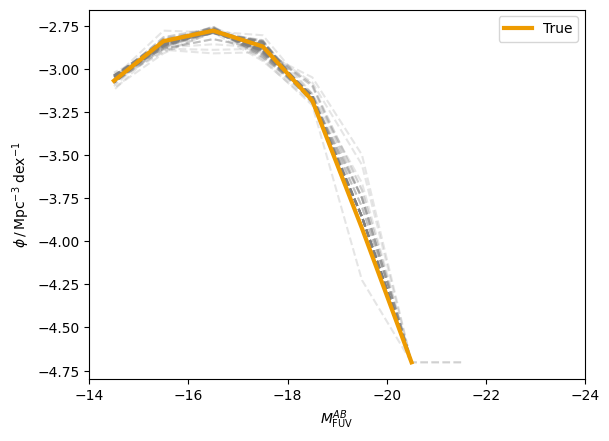

In [ ]:
fig, ax = plt.subplots(1, 1)

for i in np.arange(len(phi_samp)):
  ax.plot(bins, np.log10(phi_samp[i]), ls='dashed', color='grey', alpha=0.2)

ax.plot(bins, np.log10(phi_att[ind]), label="True", lw=3, color='#ee9b00')

ax.legend()
ax.set_xlabel(r"$M_{\rm FUV}^{AB}$")
ax.set_ylabel(r"$\phi \,/\, \mathrm{Mpc^{-3} \; dex^{-1}}$")
ax.set_xlim(-14, -24)

plt.show()

Can we improve the constraints on the slope by adding in colour information? Or by adding the NUV luminosity functions? Try adding in the FUV$-$NUV colour to the data vector (using the premade `GALEXNUV` instrument, or the `GALEX` instrument collection, and widening the wavelength range to cover the NUV filter at $\sim 1700$–$3000$ Å), and see how the posterior constraints improve.